# Final Model Evaluation — Italian Day-Ahead Electricity Prices (2024)

**Forecast issuance:** 12:00 on D−1, forecasting every market hour on D. All historical-price inputs are dated D−2 or earlier. **Target:** GME MGP electricity price (EUR/MWh).

**Pre-evaluation decision (from notebook 03):** ordinary linear regression with eight calendar-aligned, leakage-safe features is the primary model, chosen by July–September validation MAE (10.664 EUR/MWh). An eight-feature Random Forest with previously fixed parameters and the D−2 historical baseline are prespecified comparators. No tuning or model selection takes place using the final test.

**Important limitation:** October–December 2024 was already inspected during earlier project exploration. The period is therefore a **previously inspected holdout**, not a pristine unseen test. We report it transparently and avoid adapting models to its results.


## 1. Read and validate the GME workbook

Place the original official GME workbook at `data/Anno 2024_12.xlsx` relative to the repository root. It is not redistributed here. Run this notebook from the `notebooks/` folder.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

data_path = Path("../data/Anno 2024_12.xlsx")
if not data_path.is_file():
    raise FileNotFoundError(f"Missing GME workbook: {data_path.resolve()}")

raw = pd.read_excel(data_path, sheet_name="Prezzi-Prices")
df = raw.iloc[:, :3].copy()
df.columns = ["date", "hour", "price"]
df["date"] = pd.to_datetime(df["date"].astype(str), format="%Y%m%d")
df = df.sort_values(["date", "hour"]).reset_index(drop=True)

assert len(df) == 8784
assert df[["date", "hour", "price"]].notna().all().all()
assert not df.duplicated(["date", "hour"]).any()
print("Rows:", len(df), "| Days:", df["date"].nunique())
print("Daily observation counts:", df.groupby("date").size().value_counts().sort_index().to_dict())


Rows: 8784 | Days: 366
Daily observation counts: {23: 1, 24: 364, 25: 1}


## 2. Rebuild the exact eight leakage-safe features

Prices are matched by **calendar date and market hour**, not by positional row shifts. Historical observations come from D−2, D−3, D−7, and the seven dates D−2 through D−8. Complete seven-day windows are required. This handles calendar alignment across daylight-saving transitions and may exclude observations without matching history.


In [2]:
# Step 5D.3 - Calendar-aligned historical features

import pandas as pd

dayahead_safe = df[['date', 'hour', 'price']].copy()

dayahead_safe['date'] = pd.to_datetime(
    dayahead_safe['date']
)

dayahead_safe = dayahead_safe.sort_values(
    ['date', 'hour']
).reset_index(drop=True)

# Historical prices based on actual calendar dates
for lag in [2, 3, 7]:

    historical = df[['date', 'hour', 'price']].copy()

    historical['date'] = (
        pd.to_datetime(historical['date'])
        + pd.Timedelta(days=lag)
    )

    historical = historical.rename(
        columns={'price': f'price_{lag}days_ago'}
    )

    dayahead_safe = dayahead_safe.merge(
        historical,
        on=['date', 'hour'],
        how='left',
        validate='one_to_one'
    )

# Rename weekly feature
dayahead_safe = dayahead_safe.rename(
    columns={'price_7days_ago': 'price_last_week'}
)

# Calendar features
dayahead_safe['day_of_week'] = (
    dayahead_safe['date'].dt.dayofweek
)

dayahead_safe['month'] = (
    dayahead_safe['date'].dt.month
)

print("Dataset shape:", dayahead_safe.shape)

print("\nMissing values:")
print(dayahead_safe.isna().sum())

Dataset shape: (8784, 8)

Missing values:
date                 0
hour                 0
price                0
price_2days_ago     50
price_3days_ago     74
price_last_week    170
day_of_week          0
month                0
dtype: int64


In [3]:
# Step 5D.4 - Leakage-safe rolling statistics

import numpy as np

# Historical prices from t-2 to t-8
historical_features = []

for lag in range(2, 9):

    historical = df[['date', 'hour', 'price']].copy()

    historical['date'] = (
        pd.to_datetime(historical['date'])
        + pd.Timedelta(days=lag)
    )

    column_name = f'historical_price_{lag}'

    historical = historical.rename(
        columns={'price': column_name}
    )

    dayahead_safe = dayahead_safe.merge(
        historical,
        on=['date', 'hour'],
        how='left',
        validate='one_to_one'
    )

    historical_features.append(column_name)

# Require all seven historical prices
dayahead_safe['price_7day_mean'] = (
    dayahead_safe[historical_features]
    .mean(axis=1, skipna=False)
)

dayahead_safe['price_7day_std'] = (
    dayahead_safe[historical_features]
    .std(axis=1, skipna=False)
)

# Remove temporary historical columns
dayahead_safe = dayahead_safe.drop(
    columns=historical_features
)

# Check results
print("Dataset shape:", dayahead_safe.shape)

print("\nMissing values:")
print(dayahead_safe.isna().sum())

print("\nFirst valid observations:")
print(
    dayahead_safe.dropna().head(10)
)

Dataset shape: (8784, 10)

Missing values:
date                 0
hour                 0
price                0
price_2days_ago     50
price_3days_ago     74
price_last_week    170
day_of_week          0
month                0
price_7day_mean    200
price_7day_std     200
dtype: int64

First valid observations:
          date  hour      price  price_2days_ago  price_3days_ago  \
192 2024-01-09     1   87.53150            96.85            97.50   
193 2024-01-09     2   86.18151            96.58            97.67   
194 2024-01-09     3   85.00494            93.80            93.00   
195 2024-01-09     4   84.08453            93.80            93.00   
196 2024-01-09     5   84.97701            85.93            89.70   
197 2024-01-09     6   89.34054            84.30            89.47   
198 2024-01-09     7  106.76125            85.00            91.96   
199 2024-01-09     8  117.98000           102.27            96.75   
200 2024-01-09     9  131.37280           100.55            94.66 

## 3. Reproduce chronological split and feature checks

January–June: initial training; July–September: historical validation; October–December: previously inspected test. For final evaluation, refit the already selected configurations on January–September combined, without changing hyperparameters.


In [4]:

# Step 5D.5 - Prepare leakage-safe datasets

# Remove observations without complete historical features
dayahead_safe_clean = dayahead_safe.dropna(
    subset=[
        'price_2days_ago',
        'price_3days_ago',
        'price_last_week',
        'price_7day_mean',
        'price_7day_std'
    ]
).copy()

# Chronological split
train_safe = dayahead_safe_clean[
    dayahead_safe_clean['date'] < '2024-07-01'
].copy()

val_safe = dayahead_safe_clean[
    (dayahead_safe_clean['date'] >= '2024-07-01') &
    (dayahead_safe_clean['date'] < '2024-10-01')
].copy()

test_safe = dayahead_safe_clean[
    dayahead_safe_clean['date'] >= '2024-10-01'
].copy()

# Features
features_safe = [
    'hour',
    'day_of_week',
    'month',
    'price_2days_ago',
    'price_3days_ago',
    'price_last_week',
    'price_7day_mean',
    'price_7day_std'
]

X_train_safe = train_safe[features_safe]
y_train_safe = train_safe['price']

X_val_safe = val_safe[features_safe]
y_val_safe = val_safe['price']

X_test_safe = test_safe[features_safe]
y_test_safe = test_safe['price']

print("Training:", X_train_safe.shape)
print("Validation:", X_val_safe.shape)
print("Test:", X_test_safe.shape)

print("\nMissing values:")
print(X_train_safe.isna().sum())
print(X_val_safe.isna().sum())
print(X_test_safe.isna().sum())


Training: (4168, 8)
Validation: (2208, 8)
Test: (2208, 8)

Missing values:
hour               0
day_of_week        0
month              0
price_2days_ago    0
price_3days_ago    0
price_last_week    0
price_7day_mean    0
price_7day_std     0
dtype: int64
hour               0
day_of_week        0
month              0
price_2days_ago    0
price_3days_ago    0
price_last_week    0
price_7day_mean    0
price_7day_std     0
dtype: int64
hour               0
day_of_week        0
month              0
price_2days_ago    0
price_3days_ago    0
price_last_week    0
price_7day_mean    0
price_7day_std     0
dtype: int64


In [ ]:
assert len(train_safe) == 4168
assert len(val_safe) == 2208
assert len(test_safe) == 2208
assert train_safe["date"].max() < val_safe["date"].min()
assert val_safe["date"].max() < test_safe["date"].min()
assert not X_train_safe.isna().any().any()
assert not X_val_safe.isna().any().any()
print("Chronological split and missing-feature checks passed.")


## 4. Refit prespecified models on January–September

The primary model is **ordinary linear regression** on the eight features, matching notebook 03. The Random Forest uses `n_estimators=200`, `max_depth=10`, `min_samples_leaf=5`, `random_state=42`. No feature selection, hyperparameter search, or fitting on October–December occurs.


In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

train_val = pd.concat([train_safe, val_safe], ignore_index=True)
assert len(train_val) == 6376
assert train_val["date"].max() < test_safe["date"].min()
assert train_val[features_safe].notna().all().all()
assert test_safe[features_safe].notna().all().all()

X_train_val = train_val[features_safe]
y_train_val = train_val["price"]

linear_final = LinearRegression()
linear_final.fit(X_train_val, y_train_val)

rf_params = dict(n_estimators=200, max_depth=10,
                 min_samples_leaf=5, random_state=42, n_jobs=-1)
rf_final = RandomForestRegressor(**rf_params)
rf_final.fit(X_train_val, y_train_val)

print("Refit observations:", len(train_val))
print("Test observations:", len(test_safe))
print("Models refitted using January–September only.")


Refit observations: 6376
Test observations: 2208
Models refitted using January–September only.


## 5. Report final-test performance once

MAE and RMSE are measured in EUR/MWh. The D−2 baseline uses the price from the same market hour two calendar days earlier. The model ranking is **descriptive**; it does not retroactively change the validation-based primary-model selection.


In [6]:
def evaluation_metrics(actual, prediction):
    return {
        "MAE": mean_absolute_error(actual, prediction),
        "RMSE": np.sqrt(mean_squared_error(actual, prediction)),
    }

predictions = test_safe[["date", "hour", "price"]].copy()
predictions["Linear regression"] = linear_final.predict(X_test_safe)
predictions["Random Forest"] = rf_final.predict(X_test_safe)
predictions["D-2 historical baseline"] = test_safe["price_2days_ago"].to_numpy()

model_order = ["Linear regression", "Random Forest", "D-2 historical baseline"]
final_results = pd.DataFrame([
    {"Model": name, **evaluation_metrics(predictions["price"], predictions[name])}
    for name in model_order
])
print(final_results.round(3).to_string(index=False))

baseline_mae = final_results.loc[
    final_results["Model"] == "D-2 historical baseline", "MAE"
].iloc[0]
linear_mae = final_results.loc[
    final_results["Model"] == "Linear regression", "MAE"
].iloc[0]
print(f"\nLinear-regression MAE improvement vs D-2 baseline: "
      f"{100 * (baseline_mae - linear_mae) / baseline_mae:.2f}%")


                  Model    MAE   RMSE
      Linear regression 13.295 18.643
          Random Forest 13.052 18.218
D-2 historical baseline 16.657 23.591

Linear-regression MAE improvement vs D-2 baseline: 20.19%


## 6. Diagnostic analysis (descriptive; no model revisions)

Examine hourly absolute error for the **prespecified** models. The market hour may include hour 25 at the autumn daylight-saving transition. These results are for explanation only, not for changing the chosen model or parameters.


      Linear regression  Random Forest  D-2 historical baseline
hour                                                           
1                 11.11           9.83                    10.80
2                 11.87          10.57                    12.63
3                 12.85          11.96                    14.04
4                 13.03          12.36                    13.75
5                 12.79          12.07                    14.10
6                 10.76          10.57                    11.49
7                  9.32          10.03                    12.77
8                 14.42          14.91                    24.23
9                 17.07          17.41                    27.29
10                15.90          15.93                    22.48
11                14.40          15.02                    17.54
12                16.09          15.77                    20.03
13                15.29          14.86                    16.88
14                15.57          15.11  

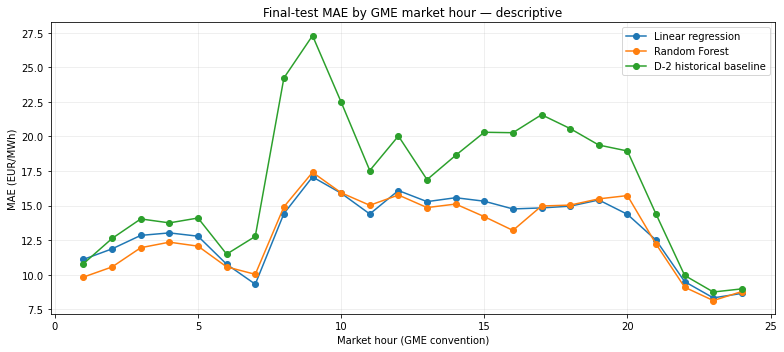

In [7]:
hourly_errors = predictions[["hour"]].copy()
for name in model_order:
    hourly_errors[name] = (predictions["price"] - predictions[name]).abs()

hourly_mae = hourly_errors.groupby("hour")[model_order].mean()
print(hourly_mae.round(2).to_string())

ax = hourly_mae.plot(figsize=(11, 5), marker="o",
                     title="Final-test MAE by GME market hour — descriptive")
ax.set_xlabel("Market hour (GME convention)")
ax.set_ylabel("MAE (EUR/MWh)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


## 7. Monthly diagnostic and forecast bias

Monthly results may reveal differences between October, November and December. The mean error is defined as **prediction minus actual**: positive values indicate overprediction, negative values indicate underprediction. These are post-hoc diagnostics only.


In [8]:
diagnostics = predictions.copy()
diagnostics["month"] = diagnostics["date"].dt.strftime("%Y-%m")
rows = []
for month, group in diagnostics.groupby("month", sort=True):
    for name in model_order:
        rows.append({
            "Month": month,
            "Model": name,
            "MAE": mean_absolute_error(group["price"], group[name]),
            "Mean error (pred - actual)": (group[name] - group["price"]).mean(),
        })
monthly_diagnostics = pd.DataFrame(rows)
print(monthly_diagnostics.round(3).to_string(index=False))


  Month                   Model    MAE  Mean error (pred - actual)
2024-10       Linear regression 11.425                      -1.154
2024-10           Random Forest 11.112                      -1.975
2024-10 D-2 historical baseline 14.636                      -1.582
2024-11       Linear regression  8.651                      -2.530
2024-11           Random Forest  8.890                      -2.170
2024-11 D-2 historical baseline 11.885                      -0.497
2024-12       Linear regression 19.659                       0.241
2024-12           Random Forest 19.019                      -3.077
2024-12 D-2 historical baseline 23.297                      -0.884


## 8. Interpretation, historical context, and limitations

The **primary model was selected on validation**, where linear regression had MAE 10.664 and RMSE 15.834 EUR/MWh, compared with the eight-feature Random Forest (MAE 11.762; RMSE 18.151) and the D−2 baseline (MAE 12.678; RMSE 19.056). Final-test results above should be discussed **regardless of which model performs best**. No test-based tuning is permitted.

**Historical project result:** the earlier Random Forest experiment reported test MAE **13.052** and RMSE **18.218**, versus a D−2 baseline MAE **16.657** and RMSE **23.591**. These values are retained as historical context, **not asserted to be identical to the results of the present reconstruction** unless verified. The reconstruction is the reproducible comparison across the same eight features and refitting protocol.

**Holdout disclosure:** this October–December period had been examined before the current notebook was prepared. The numbers are informative but not equivalent to a completely unseen prospective evaluation. A future rolling-origin or genuinely forward-time evaluation would provide stronger evidence of generalization.

**Data constraints:** the historical GME workbook is required locally; prices may vary sharply across market regimes; daylight-saving transitions produce 23- and 25-hour days; ex-ante demand, renewable output, weather and other external forecasts are not yet included.

**Next steps:** finish the portfolio documentation; then pursue Milestone 6, adding external forecasts with verified availability by the 12:00 D−1 issuance cutoff.
